# Line Chart
* ## Average Retention with Cohort Variability
* ## Month-over-Month Retention Decay
* ## Absolute Retention Drop
* ## Lifecycle Stabilization Point: Retention and Decay Dynamics

In [40]:
# Настройка отображения
pd.set_option('display.expand_frame_repr', False)
pd.set_option('display.width', None)
pd.set_option('display.max_columns', None)

## Исходные данные для построения

In [41]:
user_retention = pd.read_parquet("user_retention.parquet")
revenue_retention = pd.read_parquet("revenue_retention.parquet")
rpru_table = pd.read_parquet("rpru_table.parquet")

In [42]:
print(user_retention)

cohort_index   0         1         2         3         4         5         6         7         8         9         10
cohort_month                                                                                                         
2021-07-01    1.0  0.333876  0.345277  0.317590  0.328990  0.294788  0.280130  0.289902  0.270358  0.254072  0.239414
2021-08-01    1.0  0.284257  0.298834  0.253644  0.252187  0.233236  0.214286  0.204082  0.202624  0.172012       NaN
2021-09-01    1.0  0.301435  0.244019  0.223285  0.247209  0.186603  0.204147  0.189793  0.178628       NaN       NaN
2021-10-01    1.0  0.245115  0.266430  0.227353  0.202487  0.181172  0.179396  0.158082       NaN       NaN       NaN
2021-11-01    1.0  0.275100  0.204819  0.222892  0.198795  0.174699  0.176707       NaN       NaN       NaN       NaN
2021-12-01    1.0  0.190570  0.200393  0.161100  0.155206  0.149312       NaN       NaN       NaN       NaN       NaN
2022-01-01    1.0  0.218341  0.216157  0.189956  0.17030

In [43]:
print(revenue_retention)

cohort_index   0         1         2         3         4         5         6         7         8         9         10
cohort_month                                                                                                         
2021-07-01    1.0  0.490725  0.410814  0.501394  0.487203  0.406409  0.441578  0.367235  0.446378  0.343600  0.342857
2021-08-01    1.0  0.313988  0.338269  0.308520  0.301294  0.283371  0.270818  0.339965  0.212498  0.202365       NaN
2021-09-01    1.0  0.377895  0.282265  0.291807  0.259429  0.212711  0.268896  0.198773  0.187552       NaN       NaN
2021-10-01    1.0  0.292704  0.318131  0.289486  0.220586  0.161673  0.176723  0.145148       NaN       NaN       NaN
2021-11-01    1.0  0.249785  0.221644  0.198499  0.166038  0.147446  0.131752       NaN       NaN       NaN       NaN
2021-12-01    1.0  0.201698  0.212189  0.135877  0.155137  0.124562       NaN       NaN       NaN       NaN       NaN
2022-01-01    1.0  0.253072  0.355789  0.201810  0.17992

In [44]:
print(rpru_table)

cohort_index    0     1     2     3     4     5     6     7     8     9     10
cohort_month                                                                  
2021-07-01    1.29  1.90  1.53  2.04  1.91  1.78  2.03  1.63  2.13  1.74  1.85
2021-08-01    1.14  1.26  1.29  1.38  1.36  1.38  1.44  1.89  1.19  1.34   NaN
2021-09-01    1.30  1.63  1.50  1.70  1.36  1.48  1.71  1.36  1.37   NaN   NaN
2021-10-01    1.35  1.61  1.61  1.71  1.47  1.20  1.33  1.24   NaN   NaN   NaN
2021-11-01    1.44  1.31  1.56  1.28  1.20  1.22  1.08   NaN   NaN   NaN   NaN
2021-12-01    1.26  1.33  1.33  1.06  1.26  1.05   NaN   NaN   NaN   NaN   NaN
2022-01-01    1.26  1.46  2.08  1.34  1.33   NaN   NaN   NaN   NaN   NaN   NaN
2022-02-01    1.36  1.42  1.35  1.29   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-03-01    1.56  1.17  1.47   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-04-01    1.31  2.13   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN
2022-05-01    1.34   NaN   NaN   NaN   NaN   NaN   N

## Код для построения

In [45]:
# =====================================================
# IMPORTS
# =====================================================

import pandas as pd
import matplotlib.pyplot as plt

# =====================================================
# The meaning of colors
# =====================================================

POSITIVE = '#009E73'
NEGATIVE = '#D55E00'
USERS = '#4C72B0'

# =====================================================
# FILTER IMMATURE COHORTS
# =====================================================

# exclude last 2 immature cohorts
mature_user_retention = user_retention.iloc[:-2]
mature_revenue_retention = revenue_retention.iloc[:-2]
mature_rpru_table = rpru_table.iloc[:-2]

avg_user_retention = mature_user_retention.mean()
avg_revenue_retention = mature_revenue_retention.mean()

# =====================================================
# RETENTION DECAY ANALYSIS
# =====================================================

# relative month-over-month change
retention_decay = (
    avg_user_retention
    .pct_change()
)

revenue_decay = (
    avg_revenue_retention
    .pct_change()
)

# absolute percentage-point drop
retention_drop = (
    avg_user_retention
    .diff()
)

revenue_drop = (
    avg_revenue_retention
    .diff()
)

# =====================================================
# NUMBER OF COHORTS CONTRIBUTING
# =====================================================

cohort_counts = (
    mature_user_retention
    .count()
)

# =====================================================
# RETENTION VARIABILITY
# =====================================================

# standard deviation across cohorts
retention_std = (
    mature_user_retention
    .std()
)

revenue_retention_std = (
    mature_revenue_retention
    .std()
)

# upper/lower bounds
retention_upper = (
    avg_user_retention
    + retention_std
)

retention_lower = (
    avg_user_retention
    - retention_std
)

revenue_upper = (
    avg_revenue_retention
    + revenue_retention_std
)

revenue_lower = (
    avg_revenue_retention
    - revenue_retention_std
)


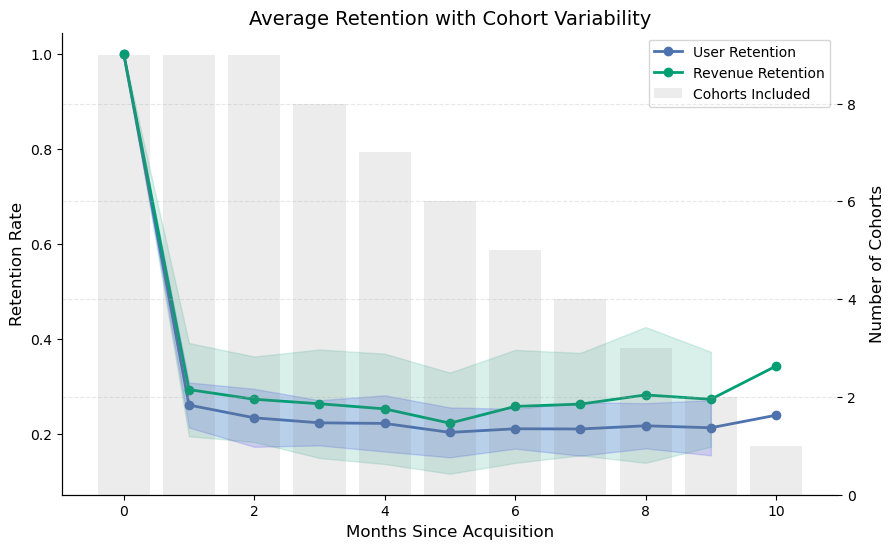

In [46]:
# =====================================================
# AVERAGE RETENTION WITH VARIABILITY
# =====================================================

fig, ax1 = plt.subplots(figsize=(10,6))


# average retention curves
ax1.plot(
    avg_user_retention.index,
    avg_user_retention.values,
    marker='o',
    linewidth=2,
    color='#4C72B0', 
    label='User Retention'
)

ax1.plot(
    avg_revenue_retention.index,
    avg_revenue_retention.values,
    marker='o',
    linewidth=2,
    color=POSITIVE,
    label='Revenue Retention'
)

# confidence bands
ax1.fill_between(
    avg_user_retention.index,
    retention_lower,
    retention_upper,
    color='blue',
    alpha=0.15
)

ax1.fill_between(
    avg_revenue_retention.index,
    revenue_lower,
    revenue_upper,
    color=POSITIVE,
    alpha=0.15
)

ax1.set_xlabel('Months Since Acquisition', fontsize=12)

ax1.set_ylabel('Retention Rate', fontsize=12)

# cohort counts
ax2 = ax1.twinx()

ax2.bar(
    cohort_counts.index,
    cohort_counts.values,
    alpha=0.15,
    color='gray',
    label='Cohorts Included'
)

ax2.set_ylabel('Number of Cohorts', fontsize=12, labelpad=10)

# combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()

ax1.legend(
    lines1 + lines2,
    labels1 + labels2,
    loc='upper right'
)

ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax2.spines['top'].set_visible(False)

plt.title('Average Retention with Cohort Variability', fontsize=14)


plt.grid(
    True,
    axis='y', 
    alpha=0.3,
    linestyle='--'
)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.savefig("average_retention.png", dpi=300, bbox_inches="tight")
plt.show()



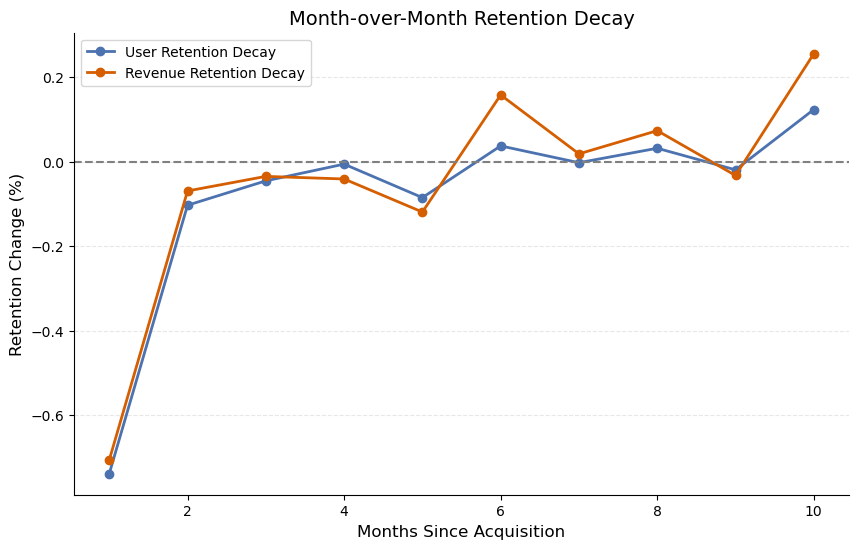

In [47]:
# =====================================================
# RETENTION DECAY CURVES
# =====================================================

plt.figure(figsize=(10,6))

plt.plot(
    retention_decay.index,
    retention_decay.values,
    marker='o',
    linewidth=2,
    color='#4C72B0',
    label='User Retention Decay'
)

plt.plot(
    revenue_decay.index,
    revenue_decay.values,
    marker='o',
    linewidth=2,
    color=NEGATIVE,
    label='Revenue Retention Decay'
)

plt.axhline(
    y=0,
    linestyle='--',
    color='gray'
)

plt.title('Month-over-Month Retention Decay', fontsize=14)

plt.xlabel('Months Since Acquisition', fontsize=12)

plt.ylabel('Retention Change (%)', fontsize=12)

plt.legend()


plt.grid(
    True,
    axis='y', 
    alpha=0.3,
    linestyle='--'
)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.savefig("relative_retention_decay.png", dpi=300, bbox_inches="tight")
plt.show()

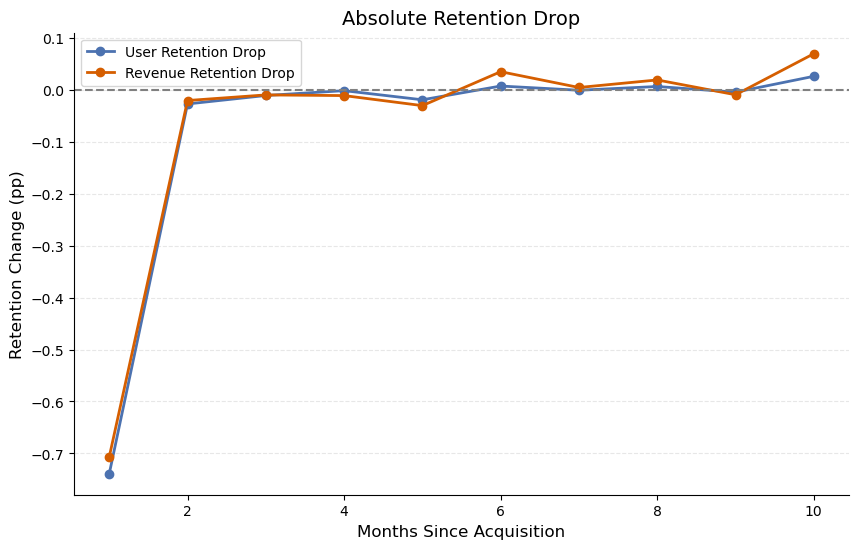

In [48]:
# =====================================================
# RETENTION DROP CURVES
# =====================================================

plt.figure(figsize=(10,6))

plt.plot(
    retention_drop.index,
    retention_drop.values,
    marker='o',
    linewidth=2,
    color= '#4C72B0',
    label='User Retention Drop'
)

plt.plot(
    revenue_drop.index,
    revenue_drop.values,
    marker='o',
    linewidth=2,
    color=NEGATIVE,
    label='Revenue Retention Drop'
)

plt.axhline(
    y=0,
    linestyle='--',
    color='gray'
)

plt.title('Absolute Retention Drop', fontsize=14)

plt.xlabel('Months Since Acquisition', fontsize=12)

plt.ylabel('Retention Change (pp)', fontsize=12)

plt.legend(loc='best')


plt.grid(
    True,
    axis='y', 
    alpha=0.3,
    linestyle='--'
)
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.savefig("absolute_retention_drop.png", dpi=300, bbox_inches="tight")
plt.show()

In [49]:
# =====================================================
# STABILIZATION POINT
# =====================================================

threshold = 0.05

stabilization_month = None

for i in range(1, len(retention_drop) - 1):

    current_drop = abs(retention_drop.iloc[i])
    next_drop = abs(retention_drop.iloc[i + 1])

    if (
        current_drop < threshold
        and
        next_drop < threshold
    ):

        stabilization_month = retention_drop.index[i]

        break

print(
    f'Stabilization Month: {stabilization_month}'
)

Stabilization Month: 2


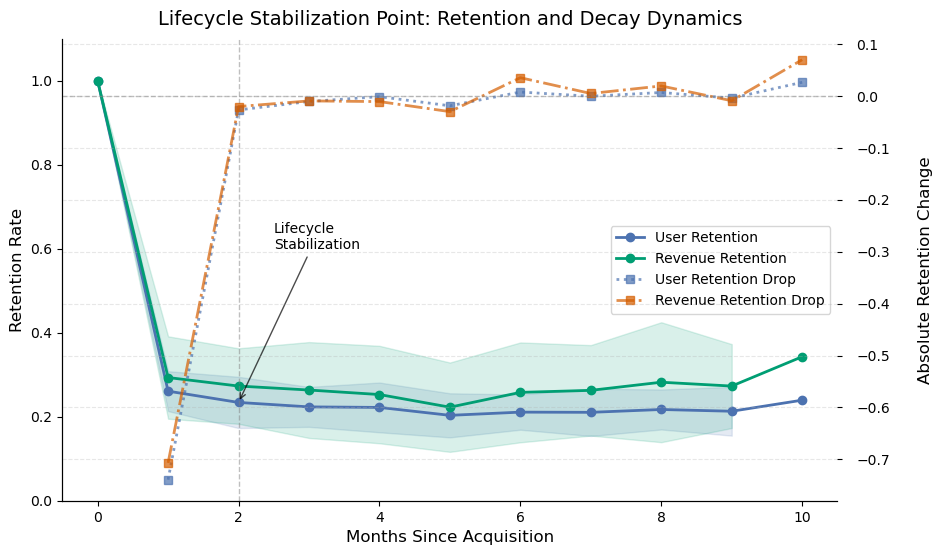

In [50]:
# =====================================================
# COMBINED RETENTION DECAY
# =====================================================

fig, ax1 = plt.subplots(
    figsize=(10,6)
)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax2.spines['top'].set_visible(False)

# =====================================================
# RETENTION CURVES
# =====================================================

line1 = ax1.plot(
    avg_user_retention.index,
    avg_user_retention.values,
    marker='o',
    linewidth=2,
    color = USERS,
    label='User Retention'
)

line2 = ax1.plot(
    avg_revenue_retention.index,
    avg_revenue_retention.values,
    marker='o',
    color = POSITIVE,
    linewidth=2,
    label='Revenue Retention'
)

# =====================================================
# CONFIDENCE BAND
# =====================================================

ax1.fill_between(
    avg_user_retention.index,
    retention_lower,
    retention_upper,
    color = USERS,
    alpha=0.15
)

ax1.fill_between(
    avg_revenue_retention.index,
    revenue_lower,
    revenue_upper,
    color = POSITIVE,
    alpha=0.15
)

# =====================================================
# STABILIZATION MARKER
# =====================================================

if stabilization_month is not None:

    ax1.axvline(
        x=stabilization_month,
        linestyle='--',
        linewidth=1,
        label='Lifecycle Stabilization Point',
        alpha = 0.5,
        color='gray'
    )

    ax1.annotate(
        'Lifecycle\nStabilization',
        xy=(
            stabilization_month,
            avg_user_retention.loc[stabilization_month]
        ),
        xytext=(
            stabilization_month + 0.5,
            avg_user_retention.max() * 0.6
        ),
        arrowprops=dict(
            arrowstyle='->',
            alpha=0.7
        )
    )

# =====================================================
# LEFT AXIS
# =====================================================

ax1.set_xlabel(
    'Months Since Acquisition',
    fontsize=12
)

ax1.set_ylabel(
    'Retention Rate',
    fontsize=12
)

ax1.set_ylim(
    0,
    max(
        avg_revenue_retention.max(),
        avg_user_retention.max()
    ) * 1.1
)

# =====================================================
# SECOND AXIS
# =====================================================

ax2 = ax1.twinx()

line3 = ax2.plot(
    retention_drop.index,
    retention_drop.values,
    marker='s',
    linewidth=2,
    linestyle=':',
    color = USERS,
    alpha=0.7,
    label='User Retention Drop'
)

line4 = ax2.plot(
    revenue_drop.index,
    revenue_drop.values,
    marker='s',
    linewidth=2,
    linestyle='-.',
    color = NEGATIVE,
    alpha=0.7,
    label='Revenue Retention Drop'
)

ax2.axhline(
    y=0,
    linestyle='--',
    linewidth=1,
    alpha = 0.5,
    color='gray'
)

ax2.set_ylabel('Absolute Retention Change', fontsize=12, labelpad=20)
ax2.tick_params(pad=10) 
# =====================================================
# LEGEND
# =====================================================

lines = (
    line1
    + line2
    + line3
    + line4
)

labels = [
    line.get_label()
    for line in lines
]

ax1.legend(
    lines,
    labels,
    loc='right'
)

# =====================================================
# TITLE
# =====================================================

plt.title(
    'Lifecycle Stabilization Point: Retention and Decay Dynamics',
    fontsize=14,
    pad= 10
)

plt.grid(
    True,
    axis='y', 
    alpha=0.3,
    linestyle='--'
)


plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)

plt.savefig("lifecycle_stabilization_point.png", dpi=300, bbox_inches="tight")

plt.show()

In [51]:
s = stabilization_summary.round(2)

s.columns = [
    'Months',
    'User Retention',
    'Revenue Retention',
    'User Drop',
    'Revenue Drop'
]

print("="*67)
print("STABILIZATION SUMMARY")
print("="*67)

print(s.round(2).to_string(index=False))

STABILIZATION SUMMARY
 Months  User Retention  Revenue Retention  User Drop  Revenue Drop
      0            1.00               1.00        NaN           NaN
      1            0.26               0.29      -0.74         -0.71
      2            0.23               0.27      -0.03         -0.02
      3            0.22               0.26      -0.01         -0.01
      4            0.22               0.25      -0.00         -0.01
      5            0.20               0.22      -0.02         -0.03
      6            0.21               0.26       0.01          0.04
      7            0.21               0.26      -0.00          0.00
      8            0.22               0.28       0.01          0.02
      9            0.21               0.27      -0.00         -0.01
     10            0.24               0.34       0.03          0.07


In [52]:
# =====================================================
# STABILIZATION SUMMARY
# =====================================================

stabilization_summary = pd.DataFrame({

    'Month': avg_user_retention.index,

    'User_Retention':
    avg_user_retention.values,

    'Revenue_Retention':
    avg_revenue_retention.values,

    'User_Drop':
    retention_drop.values,

    'Revenue_Drop':
    revenue_drop.values

})

display(
    stabilization_summary.round(3)
)

,Month,User_Retention,Revenue_Retention,User_Drop,Revenue_Drop
0,0,1.000,1.000,NaN,NaN
1,1,0.261,0.293,-0.739,-0.707
2,2,0.234,0.273,-0.027,-0.020
3,3,0.223,0.264,-0.011,-0.009
4,4,0.222,0.253,-0.001,-0.011
5,5,0.203,0.223,-0.019,-0.030
6,6,0.211,0.258,0.008,0.035
7,7,0.210,0.263,-0.000,0.005
8,8,0.217,0.282,0.007,0.019
9,9,0.213,0.273,-0.004,-0.009
